In [15]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("clmentbisaillon/fake-and-real-news-dataset")

print("Path to dataset files:", path)

100%|██████████| 41.0M/41.0M [00:00<00:00, 108MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/clmentbisaillon/fake-and-real-news-dataset/versions/1


In [16]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 53.7 MB/s  0:00:01


In [69]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import string
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from wordcloud import WordCloud
from collections import Counter
from sklearn.model_selection import cross_val_score
import re
from functools import lru_cache
from collections import Counter

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import (
    confusion_matrix, classification_report,
    accuracy_score, precision_score, recall_score,
    f1_score, balanced_accuracy_score,
    roc_auc_score, roc_curve,
    average_precision_score, precision_recall_curve
)
import joblib

In [70]:
fake = pd.read_csv(path + "/Fake.csv")
true = pd.read_csv(path + "/True.csv")

In [71]:
fake.head()

,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"


In [72]:
fake.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23481 entries, 0 to 23480
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    23481 non-null  object
 1   text     23481 non-null  object
 2   subject  23481 non-null  object
 3   date     23481 non-null  object
dtypes: object(4)
memory usage: 733.9+ KB


In [73]:
fake.describe()

,title,text,subject,date
count,23481,23481,23481,23481
unique,17903,17455,6,1681
top,MEDIA IGNORES Time That Bill Clinton FIRED His...,,News,"May 10, 2017"
freq,6,626,9050,46


In [74]:
true.head()

,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"


In [75]:
fake.duplicated().sum()

np.int64(3)

In [76]:
fake.drop_duplicates(inplace=True)

In [77]:
fake['subject'].unique()

array(['News', 'politics', 'Government News', 'left-news', 'US_News',
       'Middle-east'], dtype=object)

In [78]:
true.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21417 entries, 0 to 21416
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    21417 non-null  object
 1   text     21417 non-null  object
 2   subject  21417 non-null  object
 3   date     21417 non-null  object
dtypes: object(4)
memory usage: 669.4+ KB


In [79]:
true.describe()

,title,text,subject,date
count,21417,21417,21417,21417
unique,20826,21192,2,716
top,Factbox: Trump fills top jobs for his administ...,(Reuters) - Highlights for U.S. President Dona...,politicsNews,"December 20, 2017"
freq,14,8,11272,182


In [80]:
true.duplicated().sum()

np.int64(206)

In [81]:
true.drop_duplicates(inplace=True)

In [82]:
true['subject'].unique()

array(['politicsNews', 'worldnews'], dtype=object)

In [83]:
print(fake.shape)
print(true.shape)

(23478, 4)
(21211, 4)


**Adding a 'label' column to distinguish fake news from real news.**

In [84]:
true['label'] = 1
fake['label'] = 0
df=pd.concat([fake,true],axis=0)
df = df.sample(frac=1, random_state=42).reset_index(drop=True)
df.head()

,title,text,subject,date,label
0,WOW! LEFTIST LIBRARIAN REJECTS Shipment Of Chi...,"A school librarian in Cambridge, Massachusetts...",left-news,"Sep 28, 2017",0
1,Kenya opposition leader calls for calm in slum...,NAIROBI (Reuters) - Kenyan opposition leader R...,worldnews,"October 29, 2017",1
2,Egypt rejects U.S. decision to move its embass...,CAIRO (Reuters) - Egypt rejected the U.S. deci...,worldnews,"December 6, 2017",1
3,(AUDIO)NATION OF ISLAM LEADER FARRAKHAN: “WE W...,After a recent speech given by Minister Louis ...,left-news,"May 8, 2015",0
4,Trump Rally Nearly Turns Into A Full-Blown Ra...,Tensions ran high outside of a campaign rally ...,News,"March 11, 2016",0


In [85]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44689 entries, 0 to 44688
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    44689 non-null  object
 1   text     44689 non-null  object
 2   subject  44689 non-null  object
 3   date     44689 non-null  object
 4   label    44689 non-null  int64 
dtypes: int64(1), object(4)
memory usage: 1.7+ MB


#Cleaning the text

In [86]:

# Load English stopwords
stop_words = set(stopwords.words('english'))

# Apply caching to speed up repeated stemming operations
stem = lru_cache(maxsize=None)(PorterStemmer().stem)


def clean(text):
    # Convert text to lowercase and normalize quotation marks
    text = str(text).lower().replace('’', "'").replace('‘', "'")

    # Remove extra spaces, newlines, and leading/trailing whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    # Remove Reuters source prefix to prevent data leakage
    text = re.sub(r'^.{0,100}?\(reuters\)\s*-?\s*', '', text)

    # Remove URLs and website links
    text = re.sub(r'http\S+|www\S+', ' ', text)

    # Remove HTML tags
    text = re.sub(r'<.*?>', ' ', text)

    # Remove punctuation except apostrophes
    text = re.sub(r"[^\w\s']", ' ', text)

    # Split text into words and remove stopwords
    words = [w for w in text.split() if w not in stop_words]

    # Remove apostrophes, apply stemming, and join words
    return ' '.join(stem(w.replace("'", '')) for w in words)



In [87]:
# Apply text cleaning to title and article columns
df['title_clean'] = df['title'].apply(clean)
df['text_clean'] = df['text'].apply(clean)
df['final_text'] = df['title_clean'] + ' ' + df['text_clean']
df.head()

,title,text,subject,date,label,title_clean,text_clean,final_text
0,WOW! LEFTIST LIBRARIAN REJECTS Shipment Of Chi...,"A school librarian in Cambridge, Massachusetts...",left-news,"Sep 28, 2017",0,wow leftist librarian reject shipment children...,school librarian cambridg massachusett reject ...,wow leftist librarian reject shipment children...
1,Kenya opposition leader calls for calm in slum...,NAIROBI (Reuters) - Kenyan opposition leader R...,worldnews,"October 29, 2017",1,kenya opposit leader call calm slum hit deadli...,kenyan opposit leader raila odinga call calm s...,kenya opposit leader call calm slum hit deadli...
2,Egypt rejects U.S. decision to move its embass...,CAIRO (Reuters) - Egypt rejected the U.S. deci...,worldnews,"December 6, 2017",1,egypt reject u decis move embassi jerusalem fo...,egypt reject u decis move embassi jerusalem fo...,egypt reject u decis move embassi jerusalem fo...
3,(AUDIO)NATION OF ISLAM LEADER FARRAKHAN: “WE W...,After a recent speech given by Minister Louis ...,left-news,"May 8, 2015",0,audio nation islam leader farrakhan kill go us,recent speech given minist loui farrakhan took...,audio nation islam leader farrakhan kill go us...
4,Trump Rally Nearly Turns Into A Full-Blown Ra...,Tensions ran high outside of a campaign rally ...,News,"March 11, 2016",0,trump ralli nearli turn full blown race war st...,tension ran high outsid campaign ralli donald ...,trump ralli nearli turn full blown race war st...


In [88]:
# Remove rows with empty cleaned article text
print("Empty texts:", (df['text_clean'].str.len() == 0).sum())
df = df[df['text_clean'].str.len() > 0]

Empty texts: 716


In [89]:
# Same article with conflicting labels -> drop all of them
label_count = df.groupby('final_text')['label'].transform('nunique')
print("Conflicting-label rows:", (label_count > 1).sum())
df = df[label_count == 1]

Conflicting-label rows: 0


In [90]:
df = df.drop_duplicates(subset='final_text').reset_index(drop=True)
print("Final shape:", df.shape)
print("Duplicate articles:", df.duplicated(subset='final_text').sum())

Final shape: (38386, 8)
Duplicate articles: 0


In [91]:
df.head()

,title,text,subject,date,label,title_clean,text_clean,final_text
0,WOW! LEFTIST LIBRARIAN REJECTS Shipment Of Chi...,"A school librarian in Cambridge, Massachusetts...",left-news,"Sep 28, 2017",0,wow leftist librarian reject shipment children...,school librarian cambridg massachusett reject ...,wow leftist librarian reject shipment children...
1,Kenya opposition leader calls for calm in slum...,NAIROBI (Reuters) - Kenyan opposition leader R...,worldnews,"October 29, 2017",1,kenya opposit leader call calm slum hit deadli...,kenyan opposit leader raila odinga call calm s...,kenya opposit leader call calm slum hit deadli...
2,Egypt rejects U.S. decision to move its embass...,CAIRO (Reuters) - Egypt rejected the U.S. deci...,worldnews,"December 6, 2017",1,egypt reject u decis move embassi jerusalem fo...,egypt reject u decis move embassi jerusalem fo...,egypt reject u decis move embassi jerusalem fo...
3,(AUDIO)NATION OF ISLAM LEADER FARRAKHAN: “WE W...,After a recent speech given by Minister Louis ...,left-news,"May 8, 2015",0,audio nation islam leader farrakhan kill go us,recent speech given minist loui farrakhan took...,audio nation islam leader farrakhan kill go us...
4,Trump Rally Nearly Turns Into A Full-Blown Ra...,Tensions ran high outside of a campaign rally ...,News,"March 11, 2016",0,trump ralli nearli turn full blown race war st...,tension ran high outsid campaign ralli donald ...,trump ralli nearli turn full blown race war st...


# **Data Visualization**

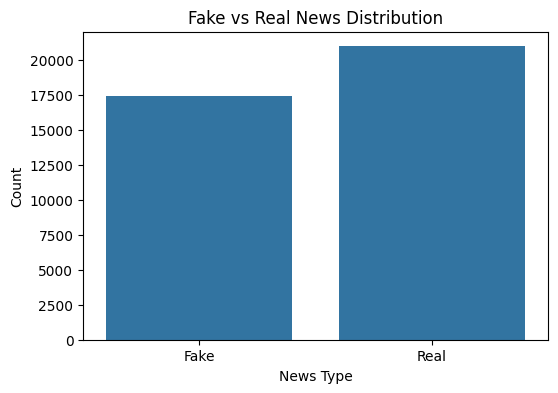

In [98]:
plt.figure(figsize=(6,4))

sns.countplot(data=df, x='label')

plt.title('Fake vs Real News Distribution')
plt.xlabel('News Type')
plt.ylabel('Count')
plt.xticks([0, 1], ['Fake', 'Real'])

plt.show()

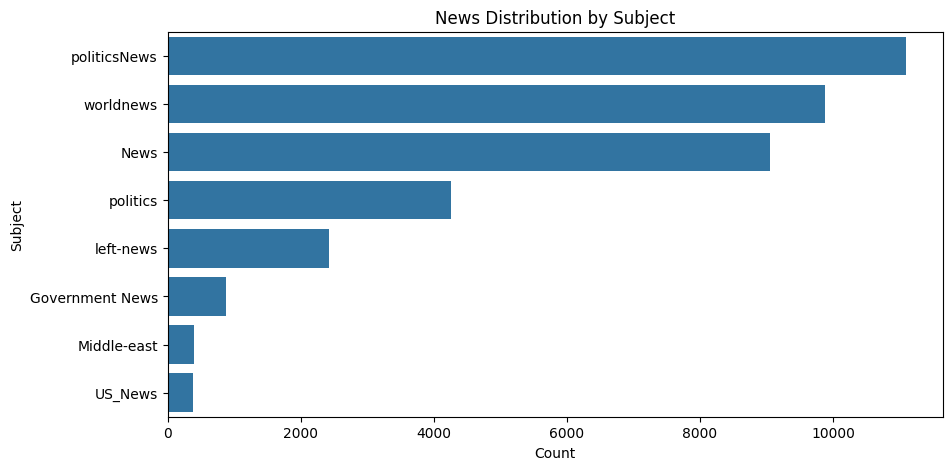

In [95]:
plt.figure(figsize=(10,5))

sns.countplot(data=df, y='subject', order=df['subject'].value_counts().index)

plt.title('News Distribution by Subject')
plt.xlabel('Count')
plt.ylabel('Subject')

plt.show()

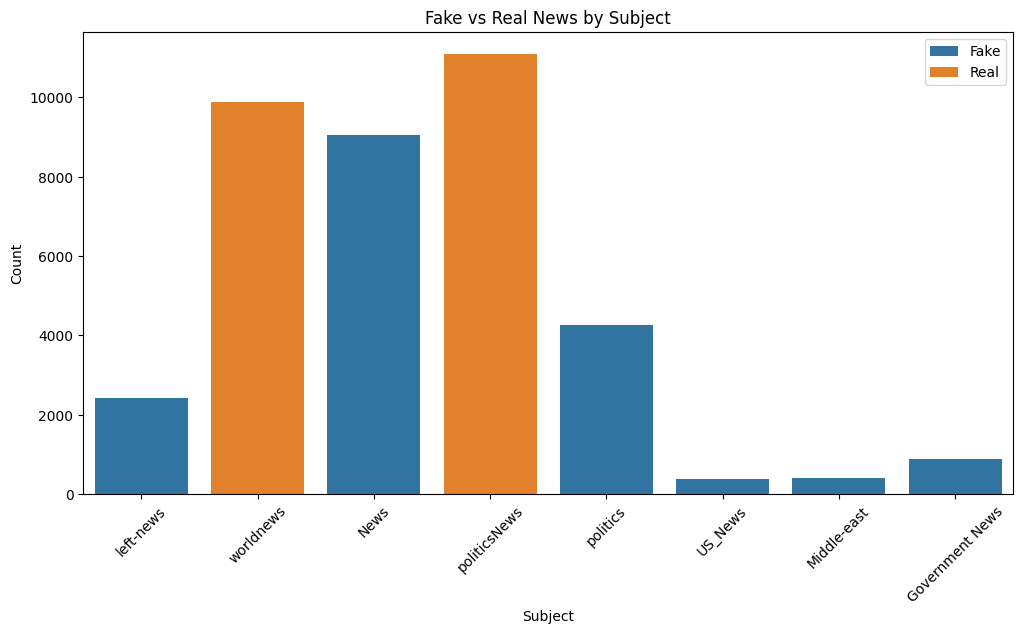

In [114]:
plt.figure(figsize=(12,6))

sns.countplot(data=df, x='subject', hue='label')

plt.title('Fake vs Real News by Subject')
plt.xlabel('Subject')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.legend(labels=['Fake', 'Real'])

plt.show()

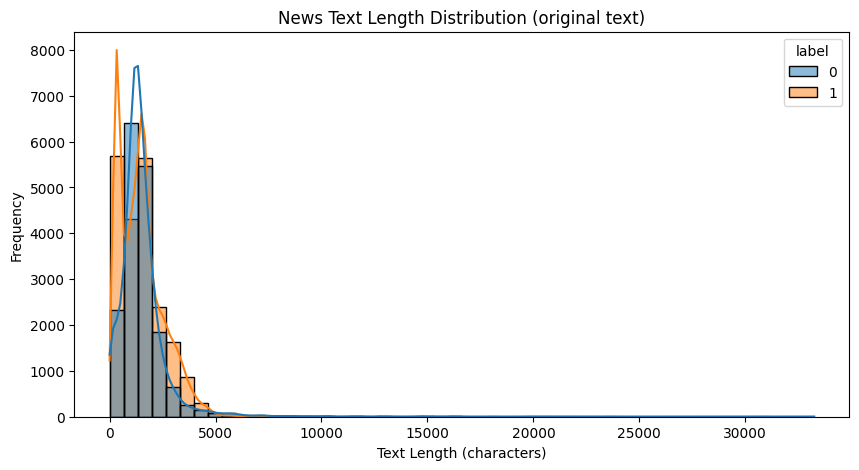

In [112]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='text_length', hue='label', bins=50, kde=True)
plt.title('News Text Length Distribution (original text)')
plt.xlabel('Text Length (characters)')
plt.ylabel('Frequency')
plt.show()

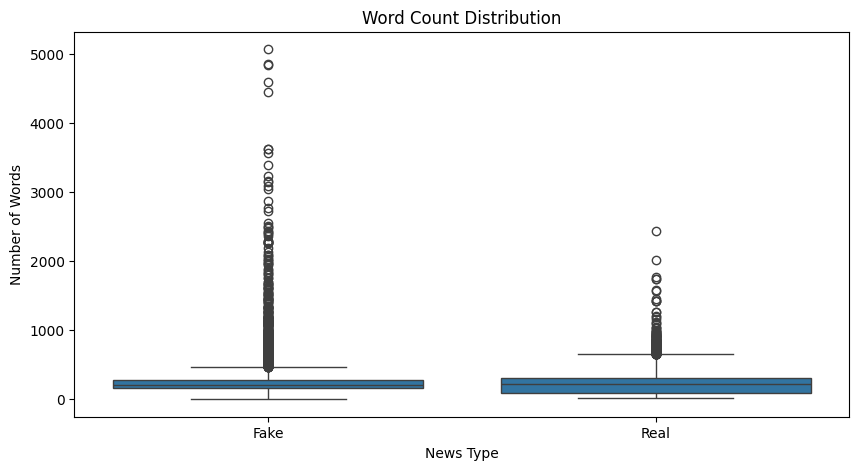

In [110]:
df['word_count'] = df['text_clean'].str.split().str.len()

plt.figure(figsize=(10,5))

sns.boxplot(data=df, x='label', y='word_count')

plt.title('Word Count Distribution')
plt.xlabel('News Type')
plt.ylabel('Number of Words')
plt.xticks([0, 1], ['Fake', 'Real'])

plt.show()

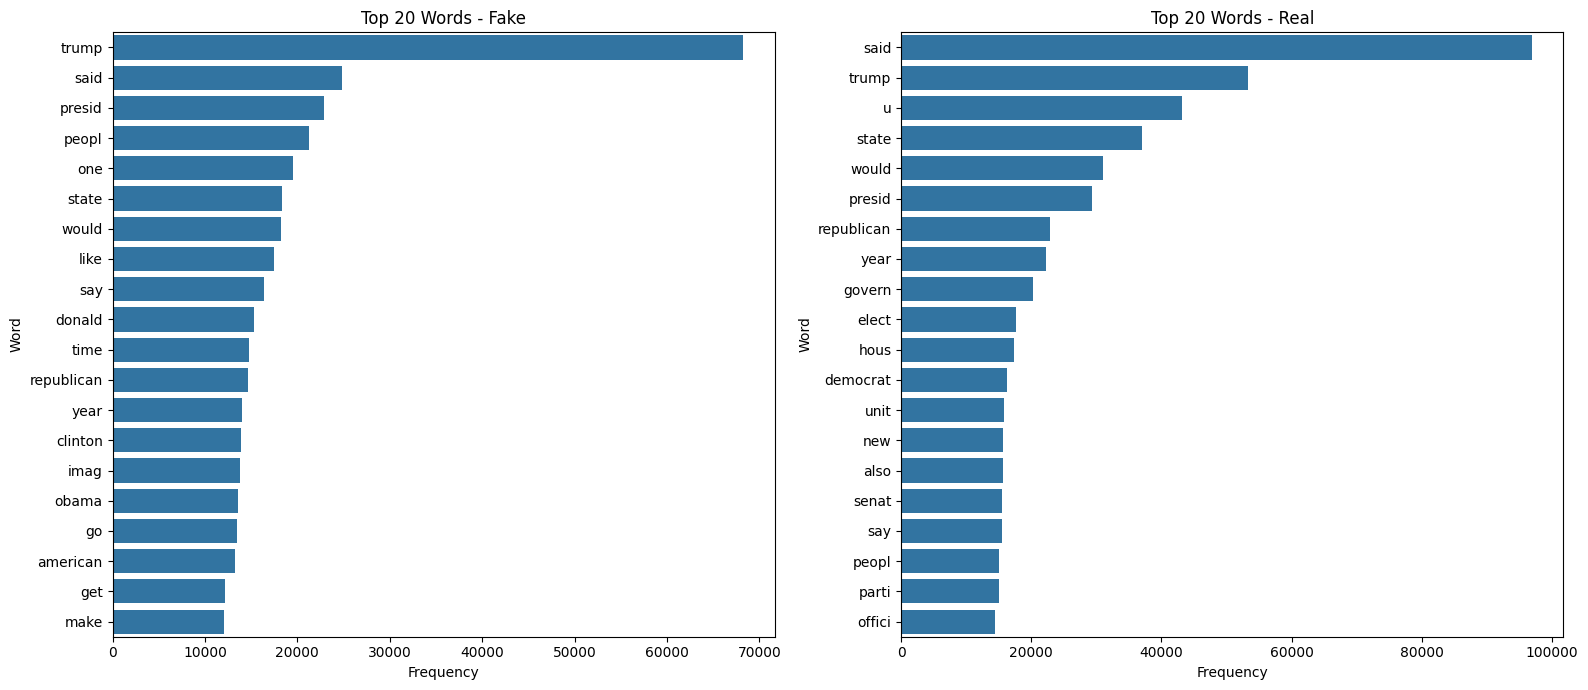

In [106]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, (lbl, name) in zip(axes, [(0, 'Fake'), (1, 'Real')]):
    words = ' '.join(df.loc[df['label'] == lbl, 'text_clean']).split()
    top = pd.DataFrame(Counter(words).most_common(20), columns=['Word', 'Frequency'])
    sns.barplot(data=top, x='Frequency', y='Word', ax=ax)
    ax.set_title(f'Top 20 Words - {name}')
plt.tight_layout()
plt.show()

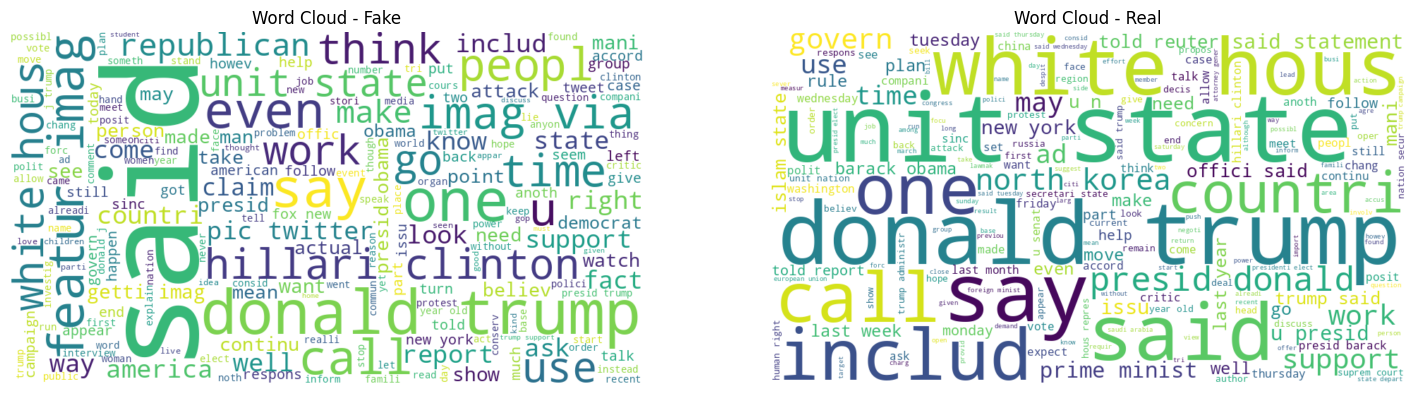

In [107]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
for ax, (lbl, name) in zip(axes, [(0, 'Fake'), (1, 'Real')]):
    text = ' '.join(df.loc[df['label'] == lbl, 'text_clean'])
    wc = WordCloud(width=900, height=500, background_color='white').generate(text)
    ax.imshow(wc, interpolation='bilinear')
    ax.axis('off')
    ax.set_title(f'Word Cloud - {name}')
plt.show()


# **Train-Test Split**

In [115]:
df['label'].value_counts()

,count
label,
1,20981
0,17405


In [116]:
X = df['final_text']
y = df['label']

In [117]:
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [118]:
tfidf = TfidfVectorizer(max_features=5000)  # TF-IDF Vectorization: Converting text into numerical features based on the importance of each word.

X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)

In [119]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (30708, 5000)
X_test: (7678, 5000)
y_train: (30708,)
y_test: (7678,)


## Models

In [120]:
models = {

    # Linear
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=1),


    # SVM
    "SVC": LinearSVC(max_iter=5000, random_state=1),

    # Tree
    "Decision Tree": DecisionTreeClassifier(random_state=1),

    # Naive Bayes
    "Naive Bayes": MultinomialNB(),

    # Bagging Based
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=1, n_jobs=-1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=1, n_jobs=-1),

    # Boosting
    "AdaBoost": AdaBoostClassifier(random_state=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=1),

    # External Boosting Libraries
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=1),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=1),
    "LightGBM": LGBMClassifier(random_state=1,verbose=-1)
}

In [121]:
for name, model in tqdm(models.items()):
    model.fit(X_train, y_train)

100%|██████████| 11/11 [23:37<00:00, 128.85s/it]


## Evaluation

In [128]:
results = []
for name, model in models.items():
    y_pred = model.predict(X_test)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
    })

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [129]:
results_df = pd.DataFrame(results).sort_values("F1", ascending=False).reset_index(drop=True)
results_df

,Model,Accuracy,Precision,Recall,F1
0,XGBoost,0.987627,0.985559,0.991899,0.988719
1,SVC,0.987497,0.986477,0.990708,0.988588
2,LightGBM,0.985673,0.983669,0.990231,0.986939
3,CatBoost,0.984110,0.980203,0.990946,0.985545
4,Logistic Regression,0.982548,0.980601,0.987610,0.984093
5,Random Forest,0.981766,0.976733,0.990231,0.983436
6,Extra Trees,0.977989,0.972548,0.987610,0.980021
7,Gradient Boosting,0.972649,0.965662,0.984989,0.975230
8,AdaBoost,0.953243,0.947111,0.968549,0.957710
9,Decision Tree,0.949987,0.953389,0.955206,0.954297


Best model: XGBoost
              precision    recall  f1-score   support

        Fake       0.99      0.98      0.99      3481
        Real       0.99      0.99      0.99      4197

    accuracy                           0.99      7678
   macro avg       0.99      0.99      0.99      7678
weighted avg       0.99      0.99      0.99      7678



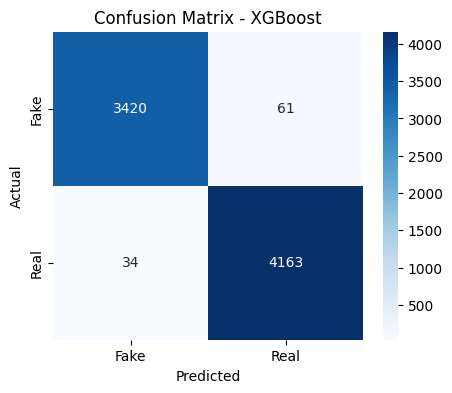

In [130]:
best_name = results_df.loc[0, "Model"]
best_model = models[best_name]
y_pred = best_model.predict(X_test)

print("Best model:", best_name)
print(classification_report(y_test, y_pred, target_names=['Fake', 'Real']))

plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=['Fake', 'Real'], yticklabels=['Fake', 'Real'])
plt.title(f'Confusion Matrix - {best_name}')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [131]:
joblib.dump(tfidf, "tfidf.joblib")
joblib.dump(best_model, "best_model.joblib")

['best_model.joblib']

In [1]:
joblib.dump(stack_auto, 'best_model.pkl')

NameError: name 'joblib' is not defined

In [ ]:
joblib.dump(tfidf, 'tfidf_vectorizer.pkl')

In [ ]:
loaded_model = joblib.load('best_model.pkl')
loaded_tfidf = joblib.load('tfidf_vectorizer.pkl')

In [ ]:
news = ["Your news article text here"]

news_tfidf = loaded_tfidf.transform(news)

prediction = loaded_model.predict(news_tfidf)

if prediction[0] == 0:
    print("Fake News")
else:
    print("Real News")